# Actividad Diagnóstica: Flujo básico de Machine Learning

**Dataset:** Titanic - Machine Learning from Disaster  
**Problema:** Clasificación  
**Variable objetivo:** Survived  

El objetivo de esta actividad es recorrer las etapas principales de un proyecto de Machine Learning, desde la exploración y limpieza de los datos hasta el entrenamiento, evaluación y registro de un modelo utilizando MLflow.

## 1. Carga y descripción del dataset

Para esta actividad se utilizará el dataset Titanic. Este conjunto de datos contiene información de pasajeros que viajaban en el Titanic, como su edad, sexo, clase del boleto y tarifa pagada.

El objetivo será predecir la variable `Survived`, que indica si un pasajero sobrevivió o no.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv("data/train.csv")

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [7]:
#Dimensiones 
print("Número de registros:", df.shape[0])
print("Número de variables:", df.shape[1])

Número de registros: 891
Número de variables: 12


In [8]:
#Tipos de variables
print(df.dtypes)
df.info()

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5)

### Descripción de las variables

- **PassengerId:** identificador único del pasajero.
- **Survived:** indica si el pasajero sobrevivió (1) o no sobrevivió (0).
- **Pclass:** clase en la que viajaba el pasajero (1, 2 o 3).
- **Name:** nombre del pasajero.
- **Sex:** sexo del pasajero.
- **Age:** edad del pasajero.
- **SibSp:** número de hermanos, hermanas o cónyuges que viajaban con el pasajero.
- **Parch:** número de padres o hijos que viajaban con el pasajero.
- **Ticket:** número del boleto.
- **Fare:** precio pagado por el boleto.
- **Cabin:** cabina asignada.
- **Embarked:** puerto de embarque.

## 2. Análisis exploratorio de datos (EDA)

En esta sección se analizarán las características principales del dataset mediante estadísticas descriptivas y visualizaciones.

In [9]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


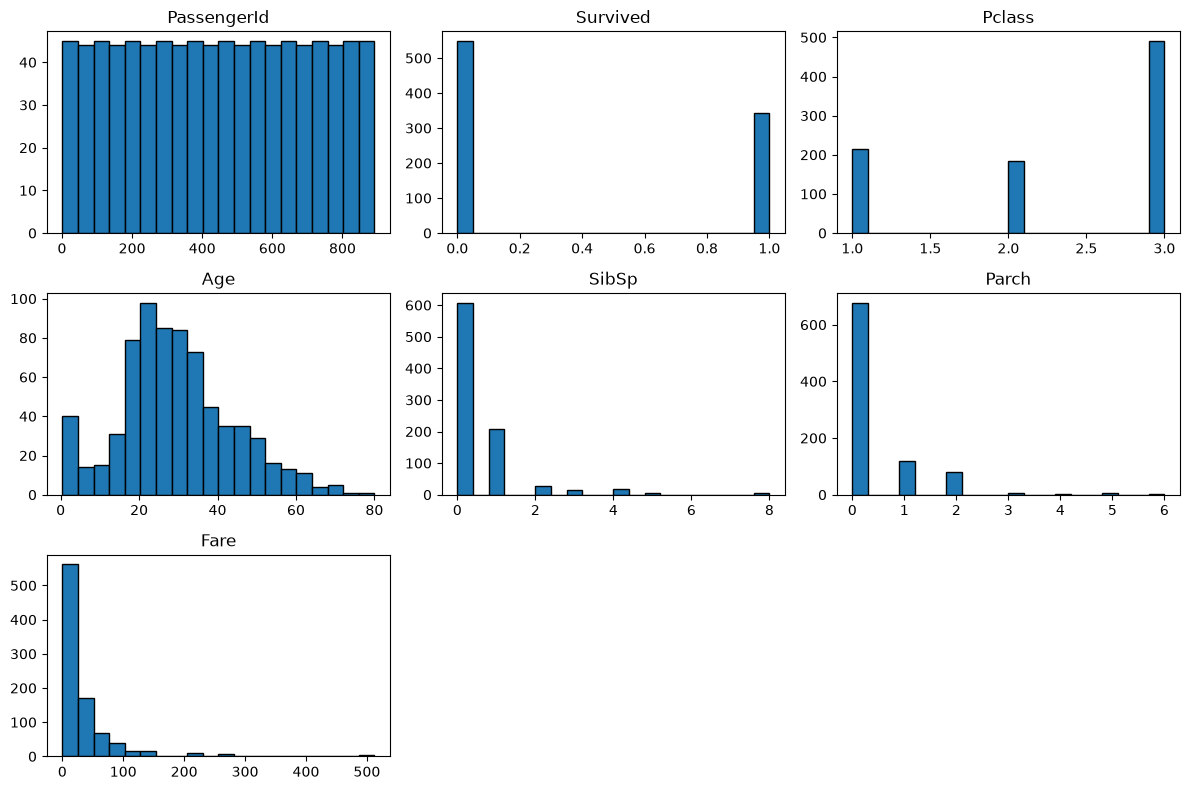

In [11]:
# Genera histogramas para todas las columnas numéricas a la vez
df.hist(figsize=(12, 8), bins=20, edgecolor='black', grid=False)

plt.tight_layout()
plt.show()

In [16]:
!pip install seaborn

Defaulting to user installation because normal site-packages is not writeable
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)


C:\Users\Guill\AppData\Local\Temp\ipykernel_44292\2412984813.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Sex', palette='Set2')


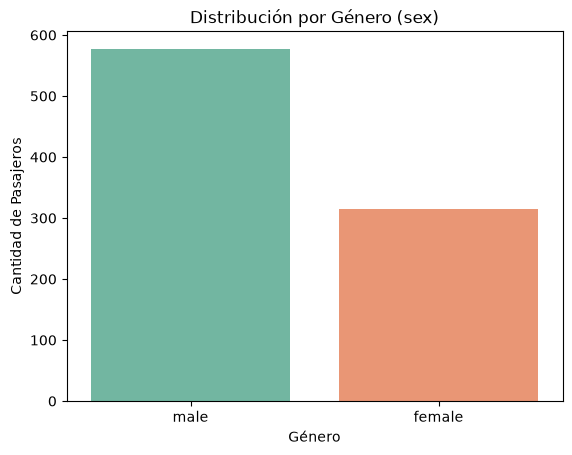

In [18]:
import seaborn as sns

# Gráfico de barras directo para una variable categórica
sns.countplot(data=df, x='Sex', palette='Set2')

plt.title('Distribución por Género (sex)')
plt.xlabel('Género')
plt.ylabel('Cantidad de Pasajeros')
plt.show()

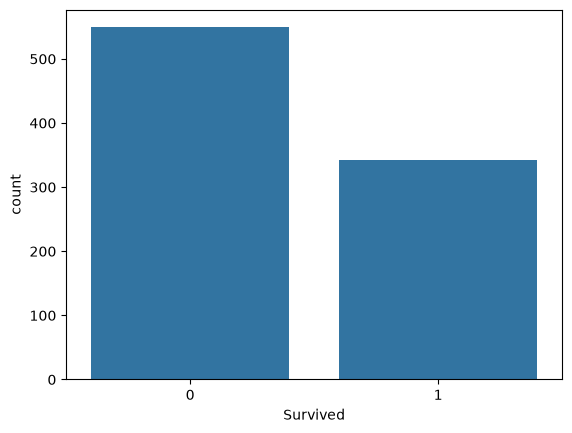

In [23]:
# Gráfico directo en una sola línea
sns.countplot(data=df, x='Survived')
plt.show()

Se observa que hubo una mayor cantidad de pasajeros que no sobrevivieron al accidente. Por lo tanto, las dos clases no tienen exactamente la misma cantidad de observaciones.

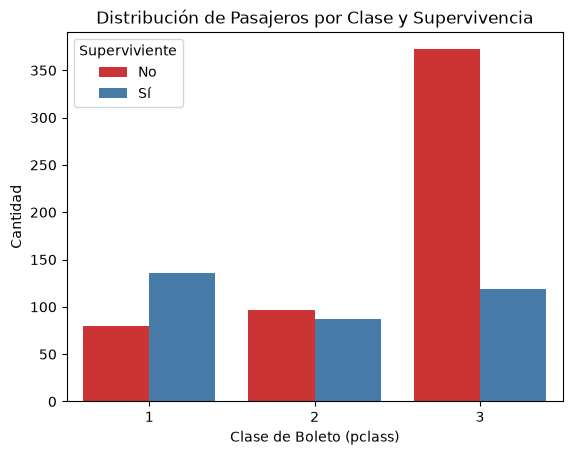

In [21]:
# Muestra la distribución de 'pclass' desglosada por 'survived'
sns.countplot(data=df, x='Pclass', hue='Survived', palette='Set1')

plt.title('Distribución de Pasajeros por Clase y Supervivencia')
plt.xlabel('Clase de Boleto (pclass)')
plt.ylabel('Cantidad')
plt.legend(title='Superviviente', labels=['No', 'Sí'])
plt.show()

También se observan diferencias en la supervivencia dependiendo de la clase del pasajero. Los pasajeros de primera clase presentan un comportamiento distinto a los pasajeros de segunda y tercera clase.

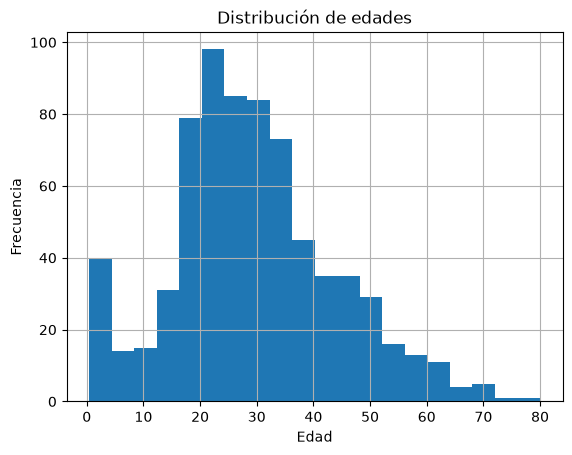

In [25]:
df["Age"].hist(bins=20)

plt.title("Distribución de edades")
plt.xlabel("Edad")
plt.ylabel("Frecuencia")

plt.show()

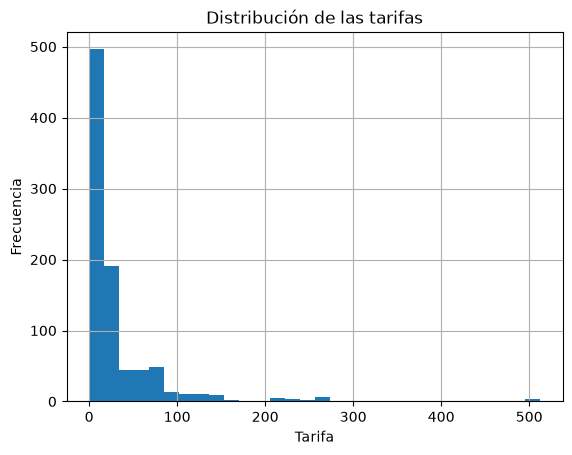

In [26]:
df["Fare"].hist(bins=30)

plt.title("Distribución de las tarifas")
plt.xlabel("Tarifa")
plt.ylabel("Frecuencia")

plt.show()

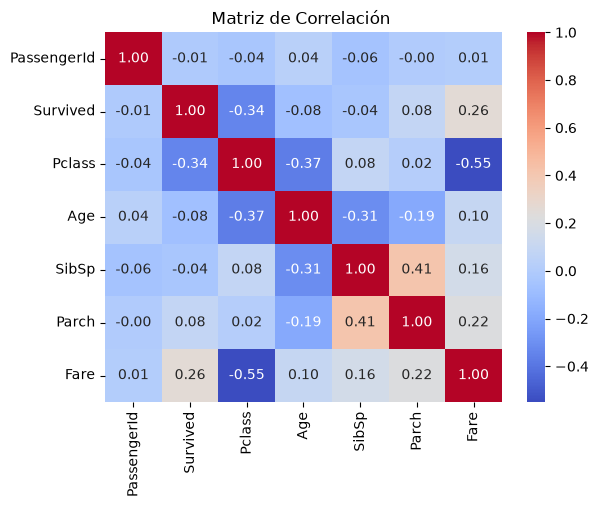

In [29]:
#Calcular la matriz de correlación (solo columnas numéricas)
matriz_corr = df.corr(numeric_only=True)

#Mostrar el mapa de calor
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriz de Correlación ')
plt.show()

## 3. Limpieza de los datos

Antes de entrenar el modelo se revisarán valores faltantes, registros duplicados, valores atípicos y los tipos de las variables.

In [30]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [31]:
porcentaje_faltantes = (df.isnull().sum() / len(df)) * 100

porcentaje_faltantes.sort_values(ascending=False)

Cabin          77.104377
Age            19.865320
Embarked        0.224467
PassengerId     0.000000
Name            0.000000
Pclass          0.000000
Survived        0.000000
Sex             0.000000
Parch           0.000000
SibSp           0.000000
Fare            0.000000
Ticket          0.000000
dtype: float64

In [32]:
df.duplicated().sum()

np.int64(0)

No se encontraron registros completamente duplicados en el dataset, por lo que no fue necesario eliminar observaciones por esta razón.

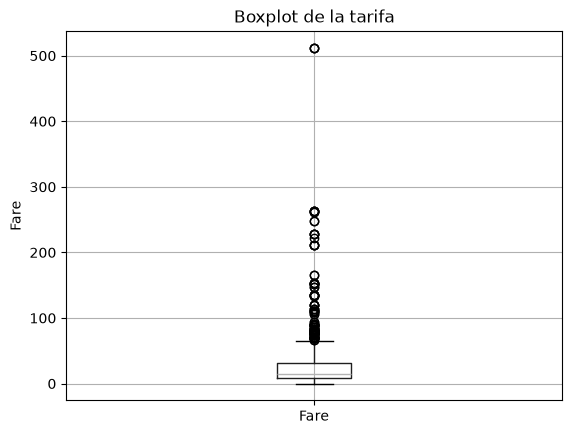

In [33]:
df.boxplot(column="Fare")

plt.title("Boxplot de la tarifa")
plt.ylabel("Fare")

plt.show()

Se identificaron valores atípicos en la variable `Fare`. Sin embargo, estos valores no necesariamente representan errores, ya que algunos pasajeros pudieron pagar tarifas considerablemente mayores por viajar en clases superiores o adquirir diferentes tipos de boletos.

Por esta razón, se decidió conservar estos registros para evitar eliminar información válida del dataset. As u vez que las variables de hermanos y familiares que se pudieron ver con outliers en las gráficas de histograma.

In [41]:
df_clean = df.copy()
df_clean = df_clean.drop(columns=["Cabin"])
df_clean["Age"] = df_clean["Age"].fillna(df_clean["Age"].median())
# Elimina las filas que tengan NaN en la columna 'Embarked'
df_clean = df_clean.dropna(subset=['Embarked'])
df_clean.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


In [42]:
df_clean.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

Para el modelo base se eliminarán las variables `PassengerId`, `Name` y `Ticket`.

`PassengerId` funciona principalmente como un identificador y no representa una característica directa del pasajero. `Name` y `Ticket` contienen información textual del pasajero. Como el objetivo de esta actividad es construir un modelo baseline sencillo, estas variables no serán utilizadas.

## 4. Entrenamiento de un modelo base

Debido a que la variable objetivo `Survived` tiene dos posibles resultados (0 o 1), el problema corresponde a clasificación binaria.

Como modelo baseline se utilizará una regresión logística. Este modelo es relativamente sencillo e interpretable, por lo que permite establecer un punto de referencia para comparar futuros modelos.

In [43]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

In [46]:
X = df_clean.drop(columns=["Survived", "PassengerId", "Name", "Ticket"])
y = df_clean["Survived"]
X.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,male,22.0,1,0,7.2500,S
1,1,female,38.0,1,0,71.2833,C
2,3,female,26.0,0,0,7.9250,S
3,1,female,35.0,1,0,53.1000,S
4,3,male,35.0,0,0,8.0500,S


In [47]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

El dataset se dividió utilizando 80 % de las observaciones para entrenamiento y 20 % para prueba.

Se utilizó `random_state=42` para que la división pueda reproducirse posteriormente. También se utilizó `stratify=y` para mantener aproximadamente la misma proporción de sobrevivientes y no sobrevivientes en ambos conjuntos.

In [48]:
variables_numericas = [
    "Pclass",
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]

variables_categoricas = [
    "Sex",
    "Embarked"
]

In [52]:
procesador = ColumnTransformer(
    transformers=[
        (
            "numericas",
            StandardScaler(),
            variables_numericas
        ),
        (
            "categoricas",
            OneHotEncoder(handle_unknown="ignore"),
            variables_categoricas
        )
    ]
)

In [53]:
modelo = Pipeline(
    steps=[
        ("procesamiento", procesador),
        ("clasificador", LogisticRegression(max_iter=1000))
    ]
)

In [54]:
modelo.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('procesamiento', ...), ('clasificador', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['Pclass','Sex','Age',...,'Parch','Fare','Embarked']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('categoricas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all

## 5. Evaluación del modelo

El modelo será evaluado utilizando accuracy, precision, recall y F1-score.

In [55]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
y_pred = modelo.predict(X_test)

In [56]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

Accuracy: 0.8089887640449438
Precision: 0.7833333333333333
Recall: 0.6911764705882353
F1-score: 0.734375


In [57]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.82      0.88      0.85       110
           1       0.78      0.69      0.73        68

    accuracy                           0.81       178
   macro avg       0.80      0.79      0.79       178
weighted avg       0.81      0.81      0.81       178



In [60]:
from sklearn.dummy import DummyClassifier
#Crear el modelo dummy
modelo_dummy = DummyClassifier(strategy='most_frequent')

# Entrenar y evaluar
modelo_dummy.fit(X_train, y_train)
precision_dummy = modelo_dummy.score(X_test, y_test)

print(f"Accuracy del Baseline (Dummy): {precision_dummy:.4f}")

Accuracy del Baseline (Dummy): 0.6180


### Interpretación de resultados

El modelo obtuvo un accuracy aproximado de 0.81, lo que significa que clasificó correctamente cerca del 81 % de los pasajeros del conjunto de prueba.

Para la clase de pasajeros que sobrevivieron, el modelo obtuvo una precisión de aproximadamente 0.78. Esto significa que de los pasajeros que el modelo predijo como sobrevivientes, alrededor del 78 % realmente sobrevivió.

El recall para la clase de sobrevivientes fue de aproximadamente 0.69. Esto indica que el modelo logró identificar correctamente cerca del 69 % de todos los pasajeros que realmente sobrevivieron.

El F1-score fue de aproximadamente 0.73 para la clase de sobrevivientes. Esta métrica combina precision y recall, por lo que ayuda a evaluar el balance entre ambas.

También se observa que el modelo tiene un mejor desempeño al identificar a los pasajeros que no sobrevivieron, ya que para la clase 0 obtuvo un recall de 0.88, mientras que para la clase 1 el recall fue de 0.69.

En general, el modelo presenta un desempeño aceptable como modelo baseline. Sin embargo, todavía existe margen de mejora, especialmente en la identificación de pasajeros que sí sobrevivieron.

El Dummy Classifier obtuvo un accuracy aproximado de 0.62, mientras que la
regresión logística obtuvo aproximadamente 0.81. Esta diferencia muestra que
el modelo de regresión logística sí está identificando patrones en las
características de los pasajeros

## 6. Registro del experimento con MLflow

MLflow será utilizado para registrar los parámetros, métricas y el modelo generado durante el experimento. Esto permite conservar un historial reproducible de las diferentes ejecuciones.

In [61]:
import mlflow
import mlflow.sklearn

from mlflow.models import infer_signature

In [62]:
mlflow.set_tracking_uri("http://127.0.0.1:5000")

mlflow.set_experiment("Actividad_Diagnostica_Titanic")

2026/10/04 21:41:45 INFO mlflow.tracking.fluent: Experiment with name 'Actividad_Diagnostica_Titanic' does not exist. Creating a new experiment.


<Experiment: artifact_location='mlflow-artifacts:/2', creation_time=1791171705868, effective_trace_archival_retention=None, experiment_id='2', last_update_time=1791171705868, lifecycle_stage='active', name='Actividad_Diagnostica_Titanic', tags={}, trace_location=None, workspace='default'>

In [63]:
with mlflow.start_run():

    # Parámetros
    mlflow.log_param("modelo", "LogisticRegression")
    mlflow.log_param("test_size", 0.20)
    mlflow.log_param("random_state", 42)
    mlflow.log_param("max_iter", 1000)

    # Métricas
    mlflow.log_metric("accuracy", accuracy)
    mlflow.log_metric("precision", precision)
    mlflow.log_metric("recall", recall)
    mlflow.log_metric("f1_score", f1)

    # Firma del modelo
    signature = infer_signature(
        X_train,
        modelo.predict(X_train)
    )

    # Modelo
    mlflow.sklearn.log_model(
        sk_model=modelo,
        name="modelo_titanic",
        signature=signature
    )

    print("Experimento registrado correctamente en MLflow.")

C:\Users\Guill\AppData\Roaming\Python\Python314\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


Experimento registrado correctamente en MLflow.
🏃 View run blushing-calf-55 at: http://127.0.0.1:5000/#/experiments/2/runs/0e124248539c4c30bd9eb9908b4e5ceb
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


## 7. Reflexión

Después de realizar este ejercicio entendí que desarrollar un modelo de Machine Learning no consiste únicamente en entrenar un algoritmo. Antes de llegar al modelo es necesario conocer los datos, revisar su calidad, identificar valores faltantes, analizar posibles valores atípicos y decidir qué variables pueden ser útiles. También considero importante poder justificar las decisiones que se toman durante cada etapa.

Si este proyecto se llevara a un ambiente real, mejoraría el flujo utilizando más prácticas de MLOps. Por ejemplo, utilizaría Github para mantener un control de versiones del código y tendría un archivo de dependencias para poder reproducir el mismo ambiente en otra computadora. También sería importante tener diferentes ambientes de desarrollo, pruebas y producción. Otra mejora sería automatizar etapas como la limpieza, el entrenamiento y la evaluación del modelo.

MLflow también sería útil para comparar diferentes modelos y configuraciones sin perder los resultados anteriores. En mi área profesional, como consultor de SAP, no trabajo directamente con modelos de Machine Learning ni con grandes volúmenes de datos de forma constante. Sin embargo, sí puedo relacionar estos aprendizajes con la importancia de la auditoría, el control de cambios y el versionamiento. En proyectos de SAP es importante saber qué cambios se hicieron, quién los realizó, en qué momento y qué versión se encuentra en uso. Esto se parece a lo que se busca en MLOps al registrar experimentos, parámetros, métricas y versiones de modelos. Aunque el contexto sea diferente, la idea de mantener trazabilidad y reproducibilidad se puede extender a muchas áreas de desarrollo.

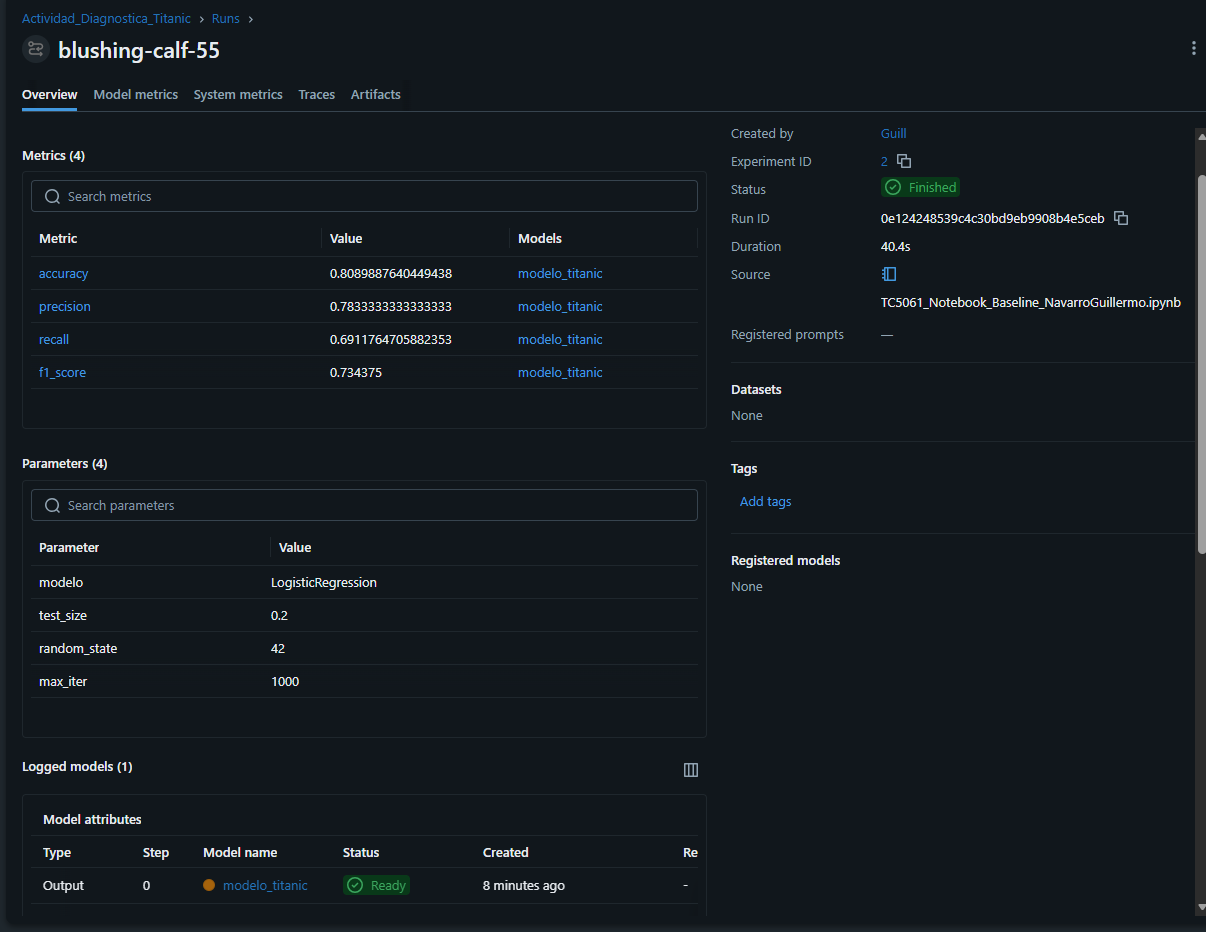

## 8. Bibliografía
OpenAI. (2026). ChatGPT (GPT-5.6 Sol) [Modelo de lenguaje grande]. Utilizado como apoyo para formato, redacción y resolución de dudas técnicas sobre librerías, sintaxis de Python y MLflow. https://chatgpt.com/